Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import warnings

from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

warnings.filterwarnings("ignore")

Configuration

In [2]:
# Dataset path
DATA_PATH = "data/processed/paddy_cleaned.csv"

# Experiment output directory
OUTPUT_DIR = "experiments/arima"

# ARIMA configuration
p = 1
d = 1
q = 1

# Train-test split
TRAIN_RATIO = 0.8

# Future forecast period
FORECAST_STEPS = 10

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("ARIMA Configuration")
print("Order:", (p, d, q))
print("Training ratio:", TRAIN_RATIO)
print("Forecast steps:", FORECAST_STEPS)

ARIMA Configuration
Order: (1, 1, 1)
Training ratio: 0.8
Forecast steps: 10


Load dataset

In [3]:
print("Loading paddy production dataset...")

df = pd.read_csv(DATA_PATH)

df = df.sort_values("Year")

# Set Year as the index
df.set_index("Year", inplace=True)

# Select target variable
production = df["Production 000 Mt."]

print("Dataset loaded successfully!")

print(
    f"Historical period: {production.index.min()} - "
    f"{production.index.max()}"
)

display(df.head())

Loading paddy production dataset...
Dataset loaded successfully!
Historical period: 1952 - 2012


,Production 000 Mt.
Year,
1952,604
1953,458
1954,650
1955,747
1956,574


Chronological train-test split

In [4]:
train_size = int(
    len(production) * TRAIN_RATIO
)

train = production.iloc[:train_size]

test = production.iloc[train_size:]

print("Training period:", train.index.min(), "-", train.index.max())

print("Testing period:", test.index.min(), "-", test.index.max())

print("\nTraining records:", len(train))
print("Testing records:", len(test))

Training period: 1952 - 1999
Testing period: 2000 - 2012

Training records: 48
Testing records: 13


Train ARIMA Model

In [5]:
print("Training ARIMA model...")

model = ARIMA(
    train,
    order=(p, d, q)
)

model_fit = model.fit()

print("ARIMA model trained successfully!")

Training ARIMA model...
ARIMA model trained successfully!


Display model summary

In [6]:
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:     Production 000 Mt.   No. Observations:                   48
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -323.855
Date:                Mon, 23 Nov 2026   AIC                            653.710
Time:                        12:02:19   BIC                            659.260
Sample:                             0   HQIC                           655.798
                                 - 48                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1380      0.469      0.294      0.769      -0.781       1.057
ma.L1         -0.4359      0.429     -1.016      0.310      -1.277       0.405
sigma2      5.647e+04   1.42e+04      3.976      0.0

Make test predictions

In [7]:
predictions = model_fit.forecast(
    steps=len(test)
)

predictions.index = test.index

results = pd.DataFrame({
    "Actual Production": test,
    "Predicted Production": predictions
})

print("========== PREDICTIONS ==========")

display(results)

========== PREDICTIONS ==========


,Actual Production,Predicted Production
Year,,
2000,2860,2755.096559
2001,2695,2741.036702
2002,2860,2739.096830
2003,3067,2738.829182
2004,2628,2738.792254
2005,3246,2738.787159
2006,3341,2738.786456
2007,3131,2738.786359
2008,3875,2738.786345


Evaluate ARIMA model

In [8]:
mae = mean_absolute_error(
    test,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        test,
        predictions
    )
)

# Avoid division by zero
mape = np.mean(
    np.abs((test - predictions) / test)
) * 100

print("========== ARIMA EVALUATION ==========")

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

========== ARIMA EVALUATION ==========
MAE:  622.12
RMSE: 786.90
MAPE: 16.91%


Visualize actual vs predicted production

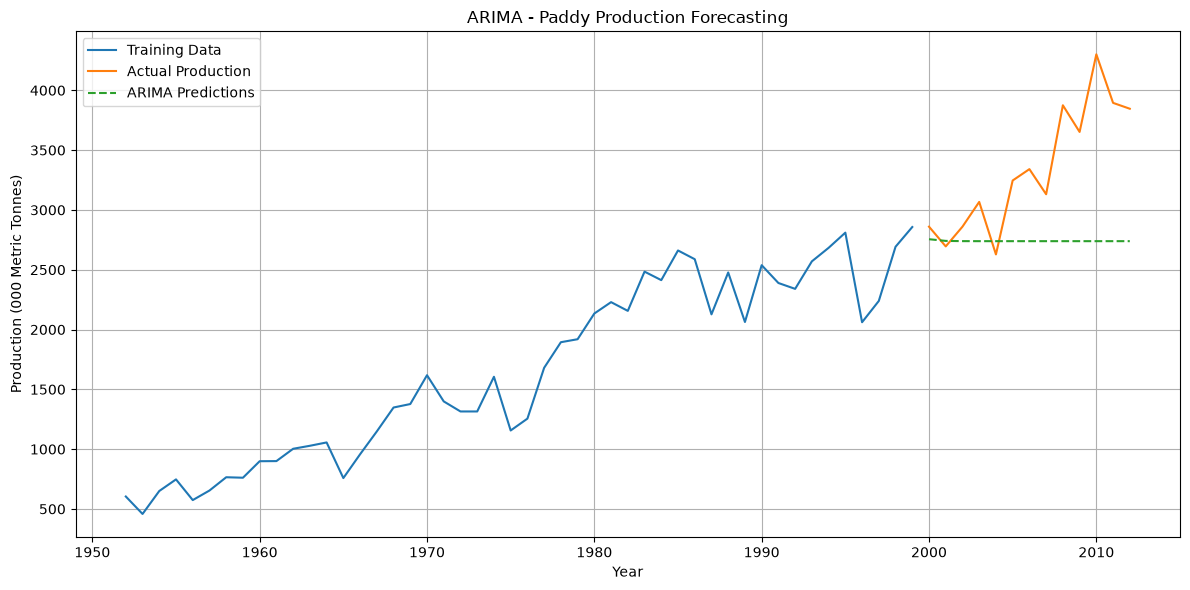

In [9]:
plt.figure(figsize=(12, 6))

plt.plot(
    train.index,
    train,
    label="Training Data"
)

plt.plot(
    test.index,
    test,
    label="Actual Production"
)

plt.plot(
    predictions.index,
    predictions,
    label="ARIMA Predictions",
    linestyle="--"
)

plt.title("ARIMA - Paddy Production Forecasting")

plt.xlabel("Year")
plt.ylabel("Production (000 Metric Tonnes)")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/arima_results.png",
    dpi=300
)

plt.show()

Refit model using all historical data

In [10]:
print("Refitting ARIMA model using all historical observations...")

final_model = ARIMA(
    production,
    order=(p, d, q)
)

final_model_fit = final_model.fit()

print("Final ARIMA model trained successfully!")

Refitting ARIMA model using all historical observations...
Final ARIMA model trained successfully!


Forecast next 10 years

In [11]:
print("========== FUTURE FORECAST ==========")

future_forecast = final_model_fit.forecast(
    steps=FORECAST_STEPS
)

future_years = range(
    int(production.index.max()) + 1,
    int(production.index.max()) + FORECAST_STEPS + 1
)

future_results = pd.DataFrame({
    "Year": future_years,
    "Forecasted Production": future_forecast.values
})

display(future_results)

========== FUTURE FORECAST ==========


,Year,Forecasted Production
0,2013,3882.514651
1,2014,3874.055828
2,2015,3876.015362
3,2016,3875.561425
4,2017,3875.666582
5,2018,3875.642222
6,2019,3875.647865
7,2020,3875.646558
8,2021,3875.646861
9,2022,3875.646790


Visualize future forecast

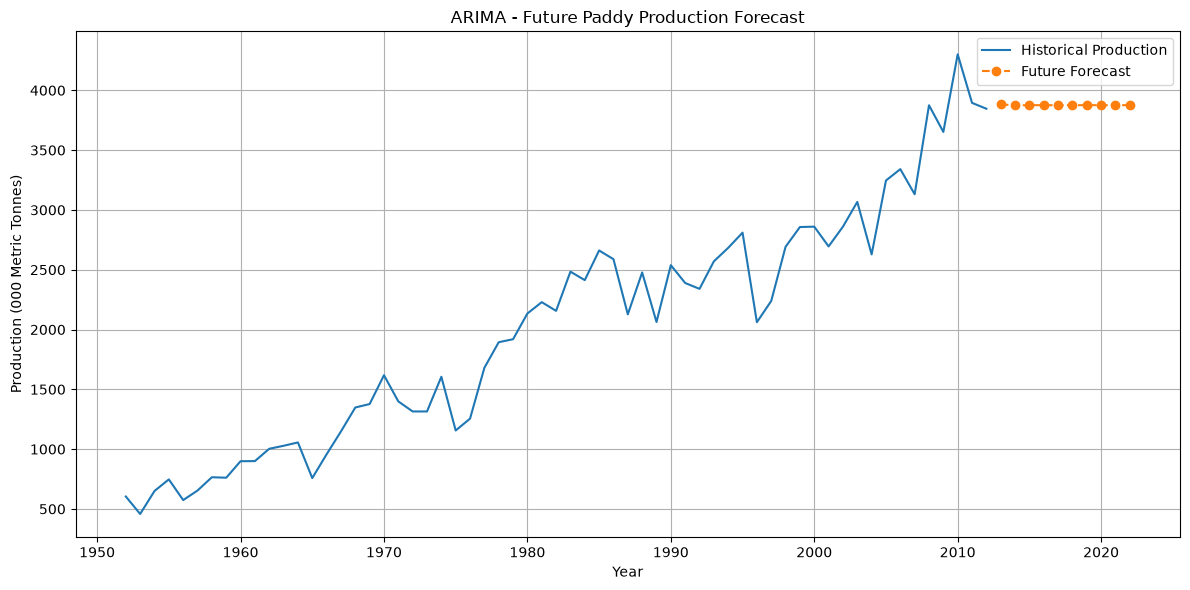

In [12]:
plt.figure(figsize=(12, 6))

plt.plot(
    production.index,
    production.values,
    label="Historical Production"
)

plt.plot(
    future_results["Year"],
    future_results["Forecasted Production"],
    label="Future Forecast",
    linestyle="--",
    marker="o"
)

plt.title("ARIMA - Future Paddy Production Forecast")

plt.xlabel("Year")
plt.ylabel("Production (000 Metric Tonnes)")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/arima_future_forecast.png",
    dpi=300
)

plt.show()

Save future forecast

In [13]:
future_results.to_csv(
    f"{OUTPUT_DIR}/future_forecast.csv",
    index=False
)

print("Future forecast saved successfully!")

Future forecast saved successfully!


Save fixed origin  predictions

In [14]:
arima_results = pd.DataFrame({
    "Year": test.index,
    "Actual": test.values,
    "Predicted": predictions.values
})

arima_results.to_csv(
    f"{OUTPUT_DIR}/fixed_origin_predictions.csv",
    index=False
)

print("ARIMA predictions saved successfully!")

ARIMA predictions saved successfully!


Final results summary

In [15]:
print("========== ARIMA MODEL SUMMARY ==========")

print("Model: ARIMA", (p, d, q))

print("Training records:", len(train))
print("Testing records:", len(test))

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

print("\nGenerated files:")

print(f"1. {OUTPUT_DIR}/arima_results.png")
print(f"2. {OUTPUT_DIR}/arima_future_forecast.png")
print(f"3. {OUTPUT_DIR}/future_forecast.csv")
print(f"4. {OUTPUT_DIR}/fixed_origin_predictions.csv")

print("\nARIMA experiment completed!")

========== ARIMA MODEL SUMMARY ==========
Model: ARIMA (1, 1, 1)
Training records: 48
Testing records: 13
MAE:  622.12
RMSE: 786.90
MAPE: 16.91%

Generated files:
1. experiments/arima/arima_results.png
2. experiments/arima/arima_future_forecast.png
3. experiments/arima/future_forecast.csv
4. experiments/arima/fixed_origin_predictions.csv

ARIMA experiment completed!
